# Alzheimer's Disease Diagnosis

This section of the exam considers the task of automatic diagnosis of Alzheimer's disease.
The data are a subset of the data analyzed by Sørensen et al. (2016, 2017), and we refer to these two studies for further background information.

Alzheimer's disease (AD) is a severe neurodegenerative disease. The vast majority of AD diagnoses are uncertain. Often, a magnetic resonance imaging (MRI) scan is part of the diagnosis, but only to rule out other causes of the symptoms. However, our work suggests that MRI scans carry much more quantitative and diagnostic information.

A system developed by DIKU and the DIKU spin-off company Biomediq can separate cognitively normal, dementia, and pre-dementia patients with high accuracy when incorporating MRI data, as demonstrated by winning   the MICCAI CADDementia Grand Challenge in 2014 (Sørensen et al., 2016, 2017).

The data in this repository are subsets of the data used by Sørensen et al. and are preprocessed in a similar way. *The system developed by Sørensen et al. distinguished between three classes: healthy, mildly cognitively impaired, and AD. However, the data sets contain only examples for healthy and AD.*



## References

L. Sørensen, C. Igel, N. Liv Hansen, M. Osler, M. Lauritzen, E. Rostrup, and M. Nielsen. Early detection of Alzheimer’s disease using MRI hippocampal texture. *Human Brain Mapping*, 37(3):1148–1161, 2016.

L. Sørensen, C. Igel, A. Pai, I. Balas, C. Anker, M. Lillholm, and M. Nielsen. Dif- ferential diagnosis of mild cognitive impairment and Alzheimer’s disease using structural MRI cortical thickness, hippocampal shape, hippocampal texture, and volumetry. *NeuroImage: Clinical*, 13:470–482, 2017.


In [15]:
import os
import warnings

# Windows warning fixes (set before importing numpy/sklearn)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

warnings.filterwarnings("ignore", message="Could not find the number of physical cores.*")
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak.*")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import scienceplots 
plt.style.use(["science", "grid"])
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})

In [16]:
# read in training data
y_train = pd.read_csv('data/trainTarget.csv',header=None)
X_train = pd.read_csv('data/trainInput.csv',header=None)
print(y_train.shape,X_train.shape)

(2430, 1) (2430, 252)


In [17]:
# read in test data
y_test = pd.read_csv('data/testTarget.csv',header=None)
X_test = pd.read_csv('data/testInput.csv',header=None)
print(y_test.shape,X_test.shape)

(270, 1) (270, 252)


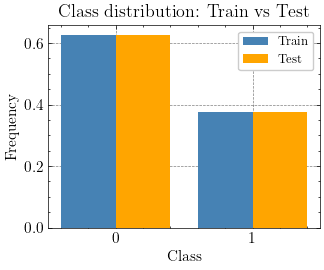

In [18]:
classes = [0, 1]
train_freq = [np.mean(y_train == c) for c in classes]
test_freq = [np.mean(y_test == c) for c in classes]

plt.bar(np.array(classes) - 0.2, train_freq, width=0.4,
        color='steelblue', label='Train')
plt.bar(np.array(classes) + 0.2, test_freq, width=0.4,
        color='orange', label='Test')

plt.xticks(classes)
plt.xlabel('Class')
plt.ylabel('Frequency')
plt.title('Class distribution: Train vs Test')
plt.legend()
plt.savefig('output/class_frequencies.png',dpi=300)
plt.show()

## Principal Component Analysis

Components needed for 90% variance: 7
Explained variance: 90.05%


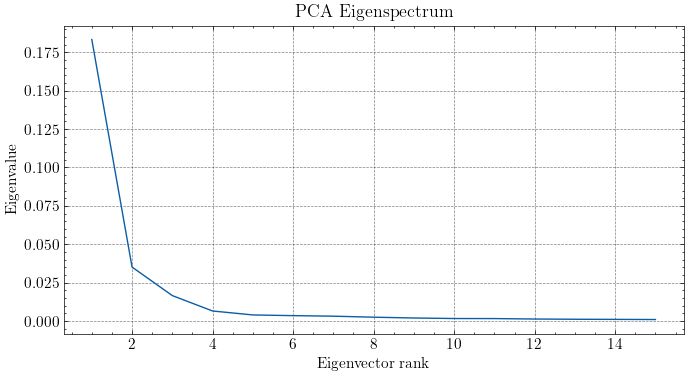

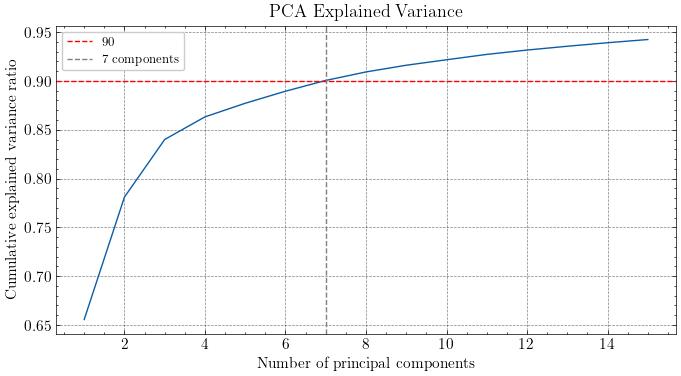

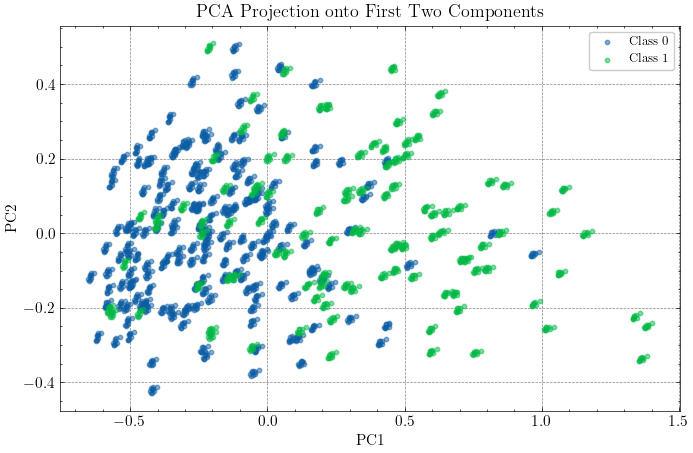

In [19]:
from sklearn.decomposition import PCA

# Load data (skip if X_train and y_train are already defined)
# X_train = pd.read_csv("trainInput.csv", header=None).to_numpy()

y = np.asarray(y_train).ravel()

# PCA (automatically centers the data)
pca = PCA(n_components=15)
X_pca = pca.fit_transform(X_train)

# Eigenvalues and explained variance
eigenvalues = pca.explained_variance_
ranks = np.arange(1, len(eigenvalues) + 1)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Number of components explaining at least 90% variance
n90 = np.searchsorted(cumulative_variance, 0.90) + 1
print(f"Components needed for 90% variance: {n90}")
print(f"Explained variance: {cumulative_variance[n90-1]:.2%}")

# 1. Eigenspectrum
plt.figure(figsize=(8, 4))
plt.plot(ranks, eigenvalues)
plt.xlabel("Eigenvector rank")
plt.ylabel("Eigenvalue")
plt.title("PCA Eigenspectrum")
plt.show()

# 2. Cumulative explained variance
plt.figure(figsize=(8, 4))
plt.plot(ranks, cumulative_variance)
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.axvline(n90, color="gray", linestyle="--", label=f"{n90} components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance ratio")
plt.title("PCA Explained Variance")
plt.legend()
plt.show()

# 3. Projection onto first two principal components
plt.figure(figsize=(8, 5))

for c in np.unique(y):
    mask = y == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                alpha=0.5, s=10, label=f"Class {c}")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection onto First Two Components")
plt.legend()
plt.show()

## k-means clustering

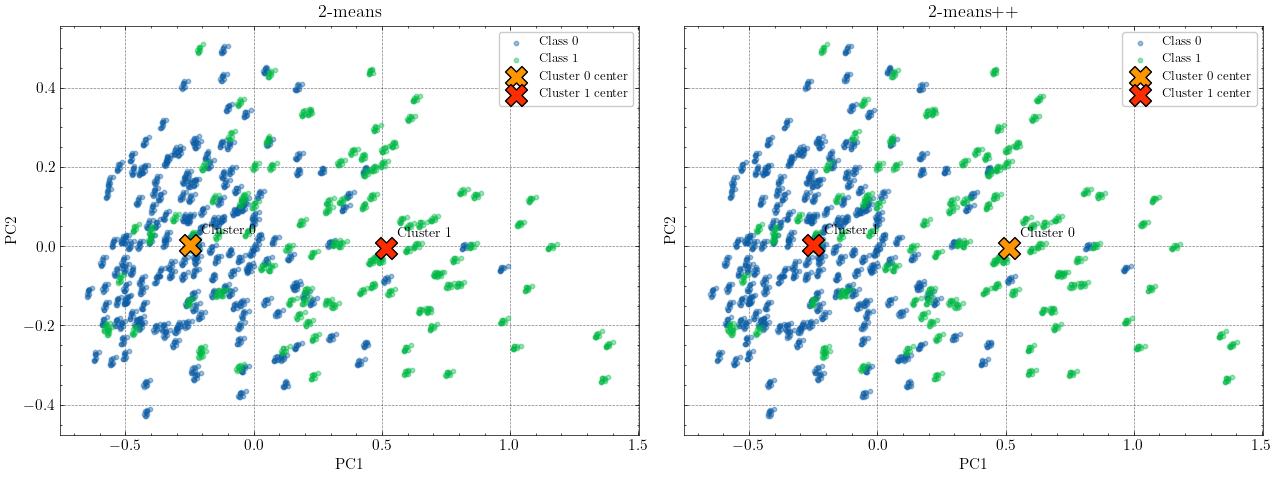


2-means | Inertia: 367.7611
Cluster        0    1
True class           
0           1338  183
1            300  609
Cluster 0: majority class 0 (81.7%)
Cluster 1: majority class 1 (76.9%)

2-means++ | Inertia: 367.7572
Cluster       0     1
True class           
0           184  1337
1           612   297
Cluster 0: majority class 1 (76.9%)
Cluster 1: majority class 0 (81.8%)


In [20]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Training data and labels
X = np.asarray(X_train)
y = np.asarray(y_train).ravel()

# PCA on original training data
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Initial centers: first observation from each class
classes = np.unique(y)
initial_idx = [np.flatnonzero(y == c)[0] for c in classes]
initial_centers = X[initial_idx]

# 1. K-means with prescribed initial centers
km = KMeans(n_clusters=2, init=initial_centers, n_init=1)
labels_km = km.fit_predict(X)

# 2. K-means++ with probabilistic initialization
kmpp = KMeans(n_clusters=2, init="k-means++", n_init=1, random_state=42)
labels_kmpp = kmpp.fit_predict(X)

# Project cluster centers onto the SAME principal components
centers_km = pca.transform(km.cluster_centers_)
centers_kmpp = pca.transform(kmpp.cluster_centers_)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for ax, centers, title in zip(
    axes,
    [centers_km, centers_kmpp],
    ["2-means", "2-means++"]
):
    for c in classes:
        mask = y == c
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                   s=10, alpha=0.4, label=f"Class {c}")

    # Plot and label individual cluster centers
    for j, center in enumerate(centers):
        ax.scatter(center[0], center[1],
                   marker="X", s=250, edgecolors="black",
                   label=f"Cluster {j} center")

        ax.annotate(f"Cluster {j}", center,
                    xytext=(8, 8), textcoords="offset points",
                    fontsize=10, fontweight="bold")

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

plt.tight_layout()
plt.show()

# Results
for name, model, labels in [
    ("2-means", km, labels_km),
    ("2-means++", kmpp, labels_kmpp)
]:
    print(f"\n{name} | Inertia: {model.inertia_:.4f}")
    print(pd.crosstab(y, labels, rownames=["True class"],
                      colnames=["Cluster"]))

    for j in range(2):
        cluster_classes = y[labels == j]
        values, counts = np.unique(cluster_classes, return_counts=True)
        majority = values[np.argmax(counts)]
        print(f"Cluster {j}: majority class {majority} "
              f"({counts.max() / len(cluster_classes):.1%})")

## Comparing k-means, Random Forest and Logistic regression

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import zero_one_loss

y_train = np.asarray(y_train).ravel()
y_test = np.asarray(y_test).ravel()

# 1. Logistic Regression
logit = LogisticRegression(
    C=np.inf,
    solver="lbfgs",
    max_iter=1000,
    random_state=69
)
logit.fit(X_train, y_train)


# 2. Random Forests
rf_params = dict(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_leaf_nodes=None,
    bootstrap=True,
    max_samples=None,
    criterion="gini",
    class_weight=None,
    oob_score=True,
    n_jobs=-1,
    random_state=69,
    verbose=0
)

# Forest 1: sqrt(number of features)
rf_sqrt = RandomForestClassifier(
    **rf_params,
    max_features="sqrt"
)
rf_sqrt.fit(X_train, y_train)

# Forest 2: all features
rf_all = RandomForestClassifier(
    **rf_params,
    max_features=None
)
rf_all.fit(X_train, y_train)


# 3. k-Nearest Neighbors (5-fold cross-validation)
knn = KNeighborsClassifier()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=69
)

grid = GridSearchCV(
    estimator=knn,
    param_grid={"n_neighbors": range(1, 31)},
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)
knn_best = grid.best_estimator_

print("Optimal k:", grid.best_params_["n_neighbors"])
print(f"Mean CV 0-1 loss: {1 - grid.best_score_:.4f}")


# 4. Evaluation
models = {
    "Logistic Regression": logit,
    "Random Forest (sqrt)": rf_sqrt,
    "Random Forest (all)": rf_all,
    "kNN (CV)": knn_best
}

results = []

for name, model in models.items():
    results.append({
        "Model": name,
        "Train 0-1 loss": zero_one_loss(y_train, model.predict(X_train)),
        "Test 0-1 loss": zero_one_loss(y_test, model.predict(X_test)),
        "OOB 0-1 loss": 1 - model.oob_score_
            if isinstance(model, RandomForestClassifier) else np.nan
    })

results = pd.DataFrame(results)
print(results.round(4).to_string(index=False))

Optimal k: 1
Mean CV 0-1 loss: 0.0000
               Model  Train 0-1 loss  Test 0-1 loss  OOB 0-1 loss
 Logistic Regression             0.0            0.0           NaN
Random Forest (sqrt)             0.0            0.0        0.0000
 Random Forest (all)             0.0            0.0        0.0012
            kNN (CV)             0.0            0.0           NaN
